In [ ]:
import warnings
warnings.filterwarnings(action="ignore", message=r"datetime.datetime.utcnow")

# PERSIAPAN

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')
os.chdir('/content/drive/MyDrive/sml') # ganti dengan folder hasil copy kalian

Mounted at /content/drive


In [ ]:
df_full = pd.read_csv("Park_Visitors.csv")
df_full.head()

,VisitorID,Gender,Age,Time Spent Hours,Distance Km,Is Weekend,Arrival Session,Exhibit Main,Spend Total
0,1,1.0,40.915235,3.086615,5.349295,No,Afternoon,Art,101.193045
1,2,0.0,51.569962,2.157987,121.142514,No,Morning,Mixed,248.219878
2,3,1.0,24.374294,4.184808,24.606314,No,Morning,NaN,133.358126
3,4,1.0,23.009726,2.701698,NaN,No,Morning,Art,96.875240
4,5,1.0,24.118024,NaN,5.365684,Yes,Afternoon,History,138.898746


In [ ]:
df = df_full.drop(columns=['VisitorID'], axis=1)
df.columns = [
    'gender',
    'age',
    'time_spent',
    'distance',
    'is_weekend',
    'arrival_session',
    'exhibit_main',
    'spend_total',
    ]
for c in ["gender"]:
  df[c] = df[c].astype("Int64").astype("object")
df.head()

,gender,age,time_spent,distance,is_weekend,arrival_session,exhibit_main,spend_total
0,1,40.915235,3.086615,5.349295,No,Afternoon,Art,101.193045
1,0,51.569962,2.157987,121.142514,No,Morning,Mixed,248.219878
2,1,24.374294,4.184808,24.606314,No,Morning,NaN,133.358126
3,1,23.009726,2.701698,NaN,No,Morning,Art,96.875240
4,1,24.118024,NaN,5.365684,Yes,Afternoon,History,138.898746


# EDA

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   gender           1807 non-null   object 
 1   age              1816 non-null   float64
 2   time_spent       1803 non-null   float64
 3   distance         1807 non-null   float64
 4   is_weekend       1808 non-null   object 
 5   arrival_session  1834 non-null   object 
 6   exhibit_main     1808 non-null   object 
 7   spend_total      2000 non-null   float64
dtypes: float64(4), object(4)
memory usage: 125.1+ KB


In [ ]:
df.describe(include = 'number')

,age,time_spent,distance,spend_total
count,1816.000000,1803.000000,1807.000000,2000.000000
mean,32.780925,3.100094,11.921787,122.461626
std,17.229982,2.440493,18.385319,50.145578
min,5.000000,0.050000,0.385231,36.241687
25%,21.864711,1.876749,4.156047,92.675489
50%,31.418635,2.523163,7.024840,111.140076
75%,41.558091,3.468478,11.811923,135.432295
max,84.000000,18.045592,242.411077,449.164829


In [ ]:
df.describe(include = ['category', 'object'])

,gender,is_weekend,arrival_session,exhibit_main
count,1807,1808,1834,1808
unique,2,2,3,4
top,1,No,Morning,Art
freq,1199,1341,806,582


# PREPROCESSING

## Data Cleaning

### Missing Value

Pemeriksaan

In [ ]:
print('Total Missing Value')
print(df.isnull().sum())

Total Missing Value
gender             193
age                184
time_spent         197
distance           193
is_weekend         192
arrival_session    166
exhibit_main       192
spend_total          0
dtype: int64


Penanganan

In [ ]:
df_no_misval = df.copy()

# Imputasi dengan rata-rata
for col in ['time_spent', 'age', 'distance', 'spend_total']:
  df_no_misval[col] = df_no_misval[col].fillna(df_no_misval[col].mean())

# Hapus baris
df_no_misval = df_no_misval.dropna(axis=0)

Pemeriksaan Kembali

In [ ]:
print('Total Missing Value')
print(df_no_misval.isnull().sum())

Total Missing Value
gender             0
age                0
time_spent         0
distance           0
is_weekend         0
arrival_session    0
exhibit_main       0
spend_total        0
dtype: int64


### Outlier

In [ ]:
def cek_outlier(df, figsize=(5, 1), dpi=100):
    kolom = df.select_dtypes(include=[np.number]).columns
    if len(kolom) == 0:
        print("Tidak ada kolom numerik.")
        return

    df_checked = df[kolom]
    df_checked.plot(
        kind="box", subplots=True,
        layout=(len(kolom), 1), figsize=(figsize[0], len(kolom) * figsize[1]),
        sharex=False, vert=False,
    )

    fig = plt.gcf()
    fig.set_dpi(dpi)
    fig.subplots_adjust(hspace=0.6)

    plt.show()

Boxplot Seluruh Variabel Numerik Sebelum Pembersihan Outlier


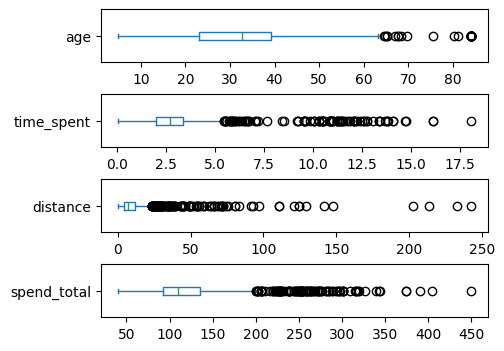

In [ ]:
print("Boxplot Seluruh Variabel Numerik Sebelum Pembersihan Outlier")
cek_outlier(df_no_misval)

Penanganan

In [ ]:
def hapus_outlier(df, kolom=None, max_iter=1):
    kolom = df.select_dtypes(include=[np.number]).columns

    df_clean = df.copy()
    for i in range(max_iter):
        before = df_clean.shape[0]

        mask = pd.Series(True, index=df_clean.index)
        for c in kolom:
            Q1, Q3 = df_clean[c].quantile([0.25, 0.75])
            IQR = Q3 - Q1
            mask &= df_clean[c].between(Q1 - 1.5*IQR, Q3 + 1.5*IQR)

        df_clean = df_clean[mask]
        after = df_clean.shape[0]

        if before == after:  # berhenti kalau tidak ada perubahan
            break
        print(f'Iterasi {i+1}: {before} -> {after} sampel')

    print(f'HASIL: {len(df)} baris dihapus dan {len(df_clean)} baris tersisa setelah {i} iterasi.')
    return df_clean

In [ ]:
df_no_outlier = df_no_misval.copy()
df_no_outlier = hapus_outlier(df_no_outlier, max_iter=10)

Iterasi 1: 1360 -> 1075 sampel
Iterasi 2: 1075 -> 990 sampel
Iterasi 3: 990 -> 981 sampel
Iterasi 4: 981 -> 979 sampel
HASIL: 1360 baris dihapus dan 979 baris tersisa setelah 4 iterasi.


Pemeriksaan Kembali

Boxplot Seluruh Variabel Numerik Setelah Pembersihan Outlier


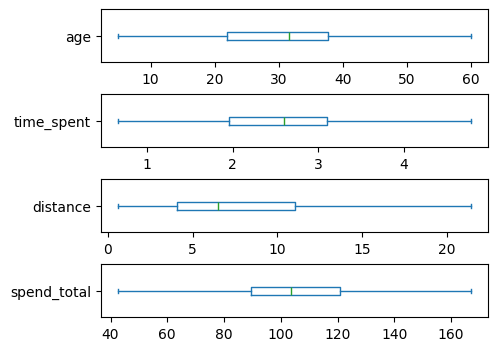

In [ ]:
print("Boxplot Seluruh Variabel Numerik Setelah Pembersihan Outlier")
cek_outlier(df_no_outlier)

### Data Duplikat

Pemeriksaan

In [ ]:
print(df_no_outlier.duplicated().sum(), 'baris terduplikat')

104 baris terduplikat


Penanganan

In [ ]:
df_no_dup = df_no_outlier.copy()
df_no_dup.drop_duplicates(inplace=True)

Pemeriksaan Kembali

In [ ]:
print(df_no_dup.duplicated().sum(), 'baris terduplikat')

0 baris terduplikat


## Splitting

In [ ]:
df_clean = df_no_dup.copy()

In [ ]:
y_col = 'spend_total'

# pisah X dan y
X = df_clean.drop(columns=y_col)
y = df_clean[y_col]

print(f'Variabel prediktor:', ', '.join(X.columns.values))
print(f'Variabel target   : {y_col}')

Variabel prediktor: gender, age, time_spent, distance, is_weekend, arrival_session, exhibit_main
Variabel target   : spend_total


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=123
)

print("Ukuran data train:", X_train.shape[0], 'baris')
print("Ukuran data test :", X_test.shape[0], 'baris')

Ukuran data train: 700 baris
Ukuran data test : 175 baris


## Encoding

In [ ]:
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns

X_train_dum = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype='uint8')
X_test_dum = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype='uint8')
X_test_dum = X_test_dum.reindex(columns=X_train_dum.columns, fill_value=0)

print(f'Ada {len(X_train_dum.columns)} variabel X.\n')
X_train_dum.info()

Ada 10 variabel X.

<class 'pandas.core.frame.DataFrame'>
Index: 700 entries, 619 to 1113
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      700 non-null    float64
 1   time_spent               700 non-null    float64
 2   distance                 700 non-null    float64
 3   gender_1                 700 non-null    uint8  
 4   is_weekend_Yes           700 non-null    uint8  
 5   arrival_session_Evening  700 non-null    uint8  
 6   arrival_session_Morning  700 non-null    uint8  
 7   exhibit_main_History     700 non-null    uint8  
 8   exhibit_main_Mixed       700 non-null    uint8  
 9   exhibit_main_Science     700 non-null    uint8  
dtypes: float64(3), uint8(7)
memory usage: 26.7 KB


## Standardisasi

In [ ]:
from sklearn.preprocessing import StandardScaler

num_cols = X_train.select_dtypes(include=[np.number]).columns

scaler = StandardScaler()
scaler.fit(X_train_dum[num_cols])

X_train_std = X_train_dum.copy()
X_test_std  = X_test_dum.copy()
X_train_std[num_cols] = scaler.transform(X_train_dum[num_cols])
X_test_std[num_cols]  = scaler.transform(X_test_dum[num_cols])

In [ ]:
pd.DataFrame({
    "mean_before": X_train_dum[num_cols].mean(),
    "std_before":  X_train_dum[num_cols].std(ddof=0),
    "mean_after":  X_train_std[num_cols].mean(),
    "std_after":   X_train_std[num_cols].std(ddof=0),
}).round(3)

,mean_before,std_before,mean_after,std_after
age,29.965,12.615,-0.0,1.0
time_spent,2.597,0.843,-0.0,1.0
distance,7.663,4.281,0.0,1.0


# ANN: REGRESI

In [ ]:
import torch
import torch.nn as nn

## Persiapan

### Konversi ke Array

In [ ]:
Xtr = torch.tensor(X_train_std.values, dtype=torch.float32)
Xte = torch.tensor(X_test_std.values,  dtype=torch.float32)

ytr = torch.tensor(y_train.values, dtype=torch.long)
yte = torch.tensor(y_test.values,  dtype=torch.long)

print('Matriks X training:')
print(Xtr)
print(f'Ukuran: {list(Xtr.shape)}')

print('\nVektor y training:')
print(ytr)
print(f'Ukuran: {list(ytr.shape)}')

Matriks X training:
tensor([[-0.7120,  0.3543, -0.3043,  ...,  0.0000,  0.0000,  1.0000],
        [-1.8997, -0.1981, -0.5197,  ...,  0.0000,  1.0000,  0.0000],
        [-1.4154, -1.6842, -0.6347,  ...,  0.0000,  1.0000,  0.0000],
        ...,
        [ 1.4921, -0.3950, -0.9520,  ...,  1.0000,  0.0000,  0.0000],
        [-1.5507, -0.3604, -1.3451,  ...,  0.0000,  0.0000,  0.0000],
        [ 0.8113, -1.8411,  0.1268,  ...,  0.0000,  0.0000,  1.0000]])
Ukuran: [700, 10]

Vektor y training:
tensor([107,  88,  66,  95,  84,  96, 121, 144,  56, 107,  94,  86, 104, 125,
        120, 114, 139, 112,  83, 109,  71, 107,  79, 102, 135, 159, 125, 107,
        154, 121, 100,  95, 111,  92,  99,  86,  80,  92,  98,  87, 141, 101,
        138,  83, 104, 105, 105, 101, 112,  83, 110, 108,  97, 136,  92,  85,
        100,  82,  75, 123,  98, 125, 150, 111,  96,  99, 104, 110, 134,  91,
         89,  89,  79,  71,  81, 101,  93, 100, 106, 132, 166, 122, 129, 134,
        101,  77, 114, 152, 111,  67, 12

### Arsitektur Model

In [ ]:
input_dim = Xtr.shape[1]
hidden_dim_1 = 16
hidden_dim_2 = 8
output_dim = 1

model = nn.Sequential(
    nn.Linear(input_dim, hidden_dim_1),
    nn.ReLU(),
    nn.Linear(hidden_dim_1, hidden_dim_2),
    nn.ReLU(),
    nn.Linear(hidden_dim_2, output_dim),
)
model

Sequential(
  (0): Linear(in_features=10, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
)

### Loss dan Optimizer

In [ ]:
loss_fn = nn.MSELoss()
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

## Training

In [ ]:
n_epochs    = 500
print_every = 50

loss_history = []
mae_history  = []
mape_history = []

for epoch in range(n_epochs):
    model.train()
    opt.zero_grad()

    preds = model(Xtr).squeeze(1)
    loss  = loss_fn(preds, ytr.float())

    loss.backward()
    opt.step()

    # hitung metrik training tiap epoch
    with torch.no_grad():
        mae_tr  = (preds - ytr).abs().mean().item()
        eps     = 1e-8
        mape_tr = ((preds - ytr).abs() / (ytr.abs() + eps)).mean().item() * 100

    # simpan ke list
    loss_history.append(loss.item())
    mae_history.append(mae_tr)
    mape_history.append(mape_tr)

    # print tiap beberapa epoch
    if (epoch + 1) % print_every == 0:
        print(
            f"Epoch {epoch+1:04d} | MSE: {loss.item():.4f} "
            f"| MAE: {mae_tr:.4f} | MAPE: {mape_tr:.2f}%"
        )

Epoch 0050 | MSE: 11348.7598 | MAE: 104.1831 | MAPE: 99.76%
Epoch 0100 | MSE: 11136.9287 | MAE: 103.1760 | MAPE: 98.77%
Epoch 0150 | MSE: 10665.2441 | MAE: 100.9100 | MAPE: 96.53%
Epoch 0200 | MSE: 9787.0566 | MAE: 96.5682 | MAPE: 92.28%
Epoch 0250 | MSE: 8376.4561 | MAE: 89.1718 | MAPE: 85.09%
Epoch 0300 | MSE: 6482.6172 | MAE: 78.1319 | MAPE: 74.40%
Epoch 0350 | MSE: 4407.3555 | MAE: 63.7355 | MAPE: 60.53%
Epoch 0400 | MSE: 2604.2175 | MAE: 47.5712 | MAPE: 45.14%
Epoch 0450 | MSE: 1428.0016 | MAE: 32.9722 | MAPE: 31.62%
Epoch 0500 | MSE: 887.5709 | MAE: 24.3771 | MAPE: 23.93%


In [ ]:
def plot_line(x, y, xlabel, ylabel, title, color=None, figsize=(6, 3), dpi=100):
    print(title)

    plt.figure(figsize=figsize, dpi=dpi)
    plt.plot(x, y, color=color)

    ax = plt.gca()
    ax.set_axisbelow(True)
    ax.grid(True, axis="y", linestyle="-", alpha=0.5)

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)

    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    plt.tight_layout()
    plt.show()

Training MSE per Epoch


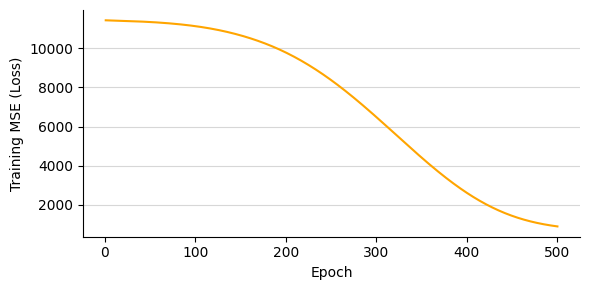


Training MAE per Epoch


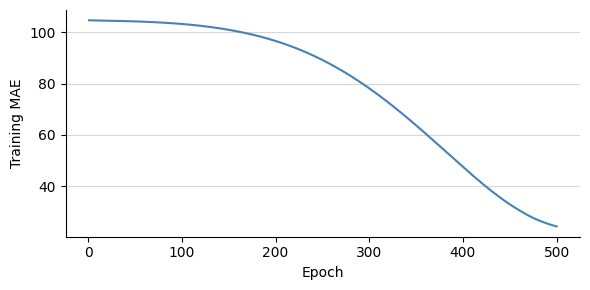


Training MAPE per Epoch


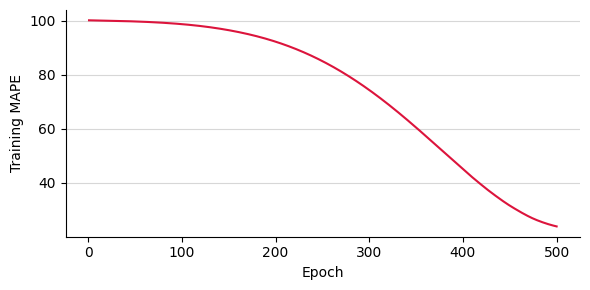

In [ ]:
epochs = range(1, n_epochs + 1)

plot_line(
    x=epochs,
    y=loss_history,
    xlabel="Epoch",
    ylabel="Training MSE (Loss)",
    title="Training MSE per Epoch",
    color="orange",
)
print()
plot_line(
    x=epochs,
    y=mae_history,
    xlabel="Epoch",
    ylabel="Training MAE",
    title="Training MAE per Epoch",
    color="steelblue",
)
print()
plot_line(
    x=epochs,
    y=mape_history,
    xlabel="Epoch",
    ylabel="Training MAPE",
    title="Training MAPE per Epoch",
    color="crimson",
)

## Testing

In [ ]:
model.eval()
with torch.no_grad():
    y_pred_tr = model(Xtr).squeeze(1)
    y_pred_te = model(Xte).squeeze(1)

train_mse = ((y_pred_tr - ytr)**2).mean().item()
test_mse  = ((y_pred_te - yte)**2).mean().item()
train_mae = (y_pred_tr - ytr).abs().mean().item()
test_mae  = (y_pred_te - yte).abs().mean().item()

eps = 1e-8
train_mape = ((y_pred_tr - ytr).abs() / (ytr.abs() + eps)).mean().item() * 100
test_mape  = ((y_pred_te - yte).abs() / (yte.abs() + eps)).mean().item() * 100

print(f"Train MSE  : {train_mse:.4f} | Train MAE  : {train_mae:.4f} | Train MAPE : {train_mape:.2f}%")
print(f"Test  MSE  : {test_mse:.4f} | Test  MAE  : {test_mae:.4f} | Test  MAPE : {test_mape:.2f}%")

Train MSE  : 881.5383 | Train MAE  : 24.2822 | Train MAPE : 23.85%
Test  MSE  : 955.0443 | Test  MAE  : 26.0555 | Test  MAPE : 25.03%


## Prediksi

In [ ]:
X_new_df = pd.DataFrame([
    {
        "age": 18,
        "time_spent": 2.5,
        "distance": 5.0,
        "gender_1": 1,
        "is_weekend_Yes": 1,
        "arrival_session_Evening": 0,
        "arrival_session_Morning": 1,
        "exhibit_main_History": 1,
        "exhibit_main_Mixed": 0,
        "exhibit_main_Science": 0,
    },
    {
        "age": 35,
        "time_spent": 4.0,
        "distance": 10.0,
        "gender_1": 0,
        "is_weekend_Yes": 0,
        "arrival_session_Evening": 1,
        "arrival_session_Morning": 0,
        "exhibit_main_History": 0,
        "exhibit_main_Mixed": 0,
        "exhibit_main_Science": 0,
    },
    {
        "age": 55,
        "time_spent": 1.5,
        "distance": 20.0,
        "gender_1": 1,
        "is_weekend_Yes": 0,
        "arrival_session_Evening": 0,
        "arrival_session_Morning": 0,
        "exhibit_main_History": 0,
        "exhibit_main_Mixed": 1,
        "exhibit_main_Science": 0,
    },
])

X_new_df = X_new_df[X_train_dum.columns]
X_new_df

,age,time_spent,distance,gender_1,is_weekend_Yes,arrival_session_Evening,arrival_session_Morning,exhibit_main_History,exhibit_main_Mixed,exhibit_main_Science
0,18,2.5,5.0,1,1,0,1,1,0,0
1,35,4.0,10.0,0,0,1,0,0,0,0
2,55,1.5,20.0,1,0,0,0,0,1,0


In [ ]:
X_new_std = X_new_df.copy()
X_new_std[num_cols] = scaler.transform(X_new_std[num_cols])

X_new = torch.tensor(X_new_std.values, dtype=torch.float32)
X_new

tensor([[-0.9484, -0.1155, -0.6221,  1.0000,  1.0000,  0.0000,  1.0000,  1.0000,
          0.0000,  0.0000],
        [ 0.3991,  1.6636,  0.5458,  0.0000,  0.0000,  1.0000,  0.0000,  0.0000,
          0.0000,  0.0000],
        [ 1.9845, -1.3016,  2.8815,  1.0000,  0.0000,  0.0000,  0.0000,  0.0000,
          1.0000,  0.0000]])

In [ ]:
model.eval()
with torch.no_grad():
    y_pred_new = model(X_new).squeeze(1).numpy()

df_hasil = X_new_df.reset_index(drop=True).copy()
df_hasil["pred_spend_total"] = y_pred_new
df_hasil

,age,time_spent,distance,gender_1,is_weekend_Yes,arrival_session_Evening,arrival_session_Morning,exhibit_main_History,exhibit_main_Mixed,exhibit_main_Science,pred_spend_total
0,18,2.5,5.0,1,1,0,1,1,0,0,114.611130
1,35,4.0,10.0,0,0,1,0,0,0,0,84.747673
2,55,1.5,20.0,1,0,0,0,0,1,0,93.780968
